# 🚦 Traffic Sign Detection & Classification
## Using Machine Learning, Deep Learning, and Transfer Learning

**Dataset Link:** https://d3ilbtxij3aepc.cloudfront.net/projects/AI-Capstone-Projects/PRAICP-1002-TrafSignDetc.zip  
**Source:** DataMites AI Capstone Project (PRAICP-1002)  

---

### Project Overview
This notebook demonstrates traffic sign classification using:
1. **ML Algorithms** — HOG + SVM, HOG + Random Forest, HOG + KNN
2. **AI Algorithm** — Custom Convolutional Neural Network (CNN)
3. **Transfer Learning** — MobileNetV2 (Pre-trained)

**HOG (Histogram of Oriented Gradients)** is used as feature extractor for ML models.  
The dataset is loaded directly from the URL — **no local download required**.

---
## 1. Install & Import Libraries

In [1]:
# Install required libraries (run once)
!pip install pillow scikit-learn scikit-image tensorflow matplotlib seaborn --quiet

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import io
import zipfile
import urllib.request
from PIL import Image
from collections import Counter

# HOG feature extraction
from skimage.feature import hog
from skimage.color import rgb2gray

# ML algorithms
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler, LabelEncoder

# AI / Deep Learning
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.utils import to_categorical

import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")
print(f"TensorFlow version: {tf.__version__}")

All libraries imported successfully!
TensorFlow version: 2.20.0


---
## 2. Load Dataset from Link (In-Memory — No Local Download)

The dataset ZIP is streamed directly from the URL into memory.  
Images are extracted and processed in RAM — **nothing is saved to your local PC**.

In [3]:
# Dataset URL provided in the project document
DATASET_URL = "https://d3ilbtxij3aepc.cloudfront.net/projects/AI-Capstone-Projects/PRAICP-1002-TrafSignDetc.zip"

print(f"Loading dataset from:\n{DATASET_URL}")
print("\nDownloading into memory (this may take a few minutes)...\n")

# Download ZIP into memory (BytesIO — no file saved to disk)
response = urllib.request.urlopen(DATASET_URL)
zip_data = io.BytesIO(response.read())
zip_file = zipfile.ZipFile(zip_data)

# List contents of the ZIP
all_files = zip_file.namelist()
print(f"Total entries in ZIP: {len(all_files)}")

# Show folder structure (top-level directories)
top_dirs = sorted(set(f.split('/')[0] for f in all_files if '/' in f))
print(f"Top-level folders: {top_dirs[:10]}...")

# Show first 15 files
print("\nSample files:")
for f in all_files[:15]:
    print(f"  {f}")

Loading dataset from:
https://d3ilbtxij3aepc.cloudfront.net/projects/AI-Capstone-Projects/PRAICP-1002-TrafSignDetc.zip


Total entries in ZIP: 103773
Top-level folders: ['Meta', 'Test', 'Train', 'meta', 'test', 'train']...

Sample files:
  Meta.csv
  Meta/.~lock.ClassesInformation.ods#
  Meta/.~lock.ClassesInformationStrong.ods#
  Meta/0.png
  Meta/1.png
  Meta/10.png
  Meta/11.png
  Meta/12.png
  Meta/13.png
  Meta/14.png
  Meta/15.png
  Meta/16.png
  Meta/17.png
  Meta/18.png
  Meta/19.png


In [4]:
# Extract images and labels from the ZIP (in-memory)
IMG_SIZE = 32
IMAGE_EXTENSIONS = ('.png', '.jpg', '.jpeg', '.ppm', '.bmp')

images = []
labels = []
skipped = 0

print("Extracting and preprocessing images from ZIP (in memory)...\n")

for file_name in all_files:
    # Only process image files
    if not file_name.lower().endswith(IMAGE_EXTENSIONS):
        continue
    
    try:
        # Extract label from folder name
        # Typical structure: .../Train/0/image.png or .../0/image.png
        parts = file_name.replace('\\', '/').split('/')
        # Find the numeric folder (class label)
        label = None
        for part in parts:
            if part.isdigit():
                label = int(part)
                break
        
        if label is None:
            skipped += 1
            continue
        
        # Read image from ZIP into memory
        img_data = zip_file.read(file_name)
        img = Image.open(io.BytesIO(img_data)).convert('RGB')
        img = img.resize((IMG_SIZE, IMG_SIZE))
        img_array = np.array(img) / 255.0  # Normalize to [0, 1]
        
        images.append(img_array)
        labels.append(label)
        
    except Exception as e:
        skipped += 1
        continue

# Convert to numpy arrays
X = np.array(images)
y = np.array(labels)

print(f"Total images loaded: {len(X)}")
print(f"Skipped files: {skipped}")
print(f"Image shape: {X.shape}")
print(f"Number of classes: {len(np.unique(y))}")
print(f"Classes: {sorted(np.unique(y))}")

Extracting and preprocessing images from ZIP (in memory)...

Total images loaded: 78418
Skipped files: 25346
Image shape: (78418, 32, 32, 3)
Number of classes: 43
Classes: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30), np.int64(31), np.int64(32), np.int64(33), np.int64(34), np.int64(35), np.int64(36), np.int64(37), np.int64(38), np.int64(39), np.int64(40), np.int64(41), np.int64(42)]


In [5]:
# Close ZIP to free memory
zip_file.close()
del zip_data
print("ZIP file closed. All data is now in memory as numpy arrays.")

ZIP file closed. All data is now in memory as numpy arrays.


In [6]:
# Encode labels (in case class folders are not 0-indexed continuously)
le = LabelEncoder()
y_encoded = le.fit_transform(y)
NUM_CLASSES = len(le.classes_)

print(f"Number of classes: {NUM_CLASSES}")
print(f"Label mapping (first 10): {dict(zip(le.classes_[:10], range(10)))}")

Number of classes: 43
Label mapping (first 10): {np.int64(0): 0, np.int64(1): 1, np.int64(2): 2, np.int64(3): 3, np.int64(4): 4, np.int64(5): 5, np.int64(6): 6, np.int64(7): 7, np.int64(8): 8, np.int64(9): 9}


In [7]:
# Train-Test Split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

print(f"Training samples: {X_train.shape[0]}")
print(f"Test samples: {X_test.shape[0]}")
print(f"Image shape: {X_train.shape[1:]}")

Training samples: 62734
Test samples: 15684
Image shape: (32, 32, 3)


---
## 3. Data Exploration & Visualization

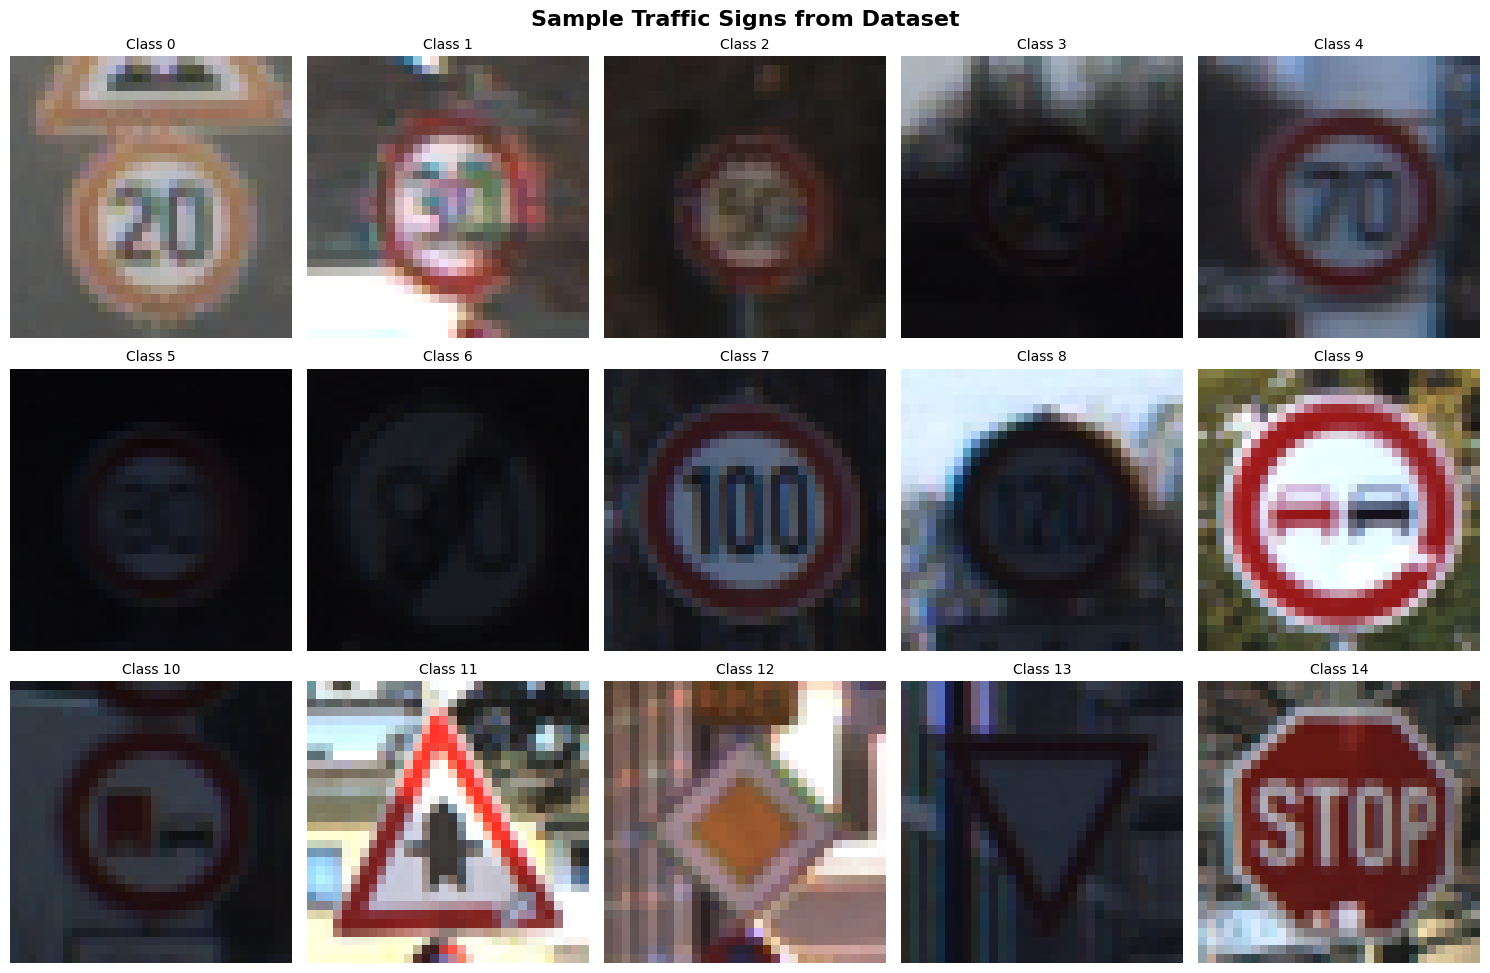

In [8]:
# Visualize sample traffic sign images
fig, axes = plt.subplots(3, 5, figsize=(15, 10))
fig.suptitle('Sample Traffic Signs from Dataset', fontsize=16, fontweight='bold')

# Show one image per class (or spread across dataset)
unique_classes = np.unique(y_train)
for i, ax in enumerate(axes.flat):
    if i < len(unique_classes):
        cls = unique_classes[i]
        idx = np.where(y_train == cls)[0][0]
        ax.imshow(X_train[idx])
        ax.set_title(f'Class {le.classes_[cls]}', fontsize=10)
    ax.axis('off')

plt.tight_layout()
plt.show()

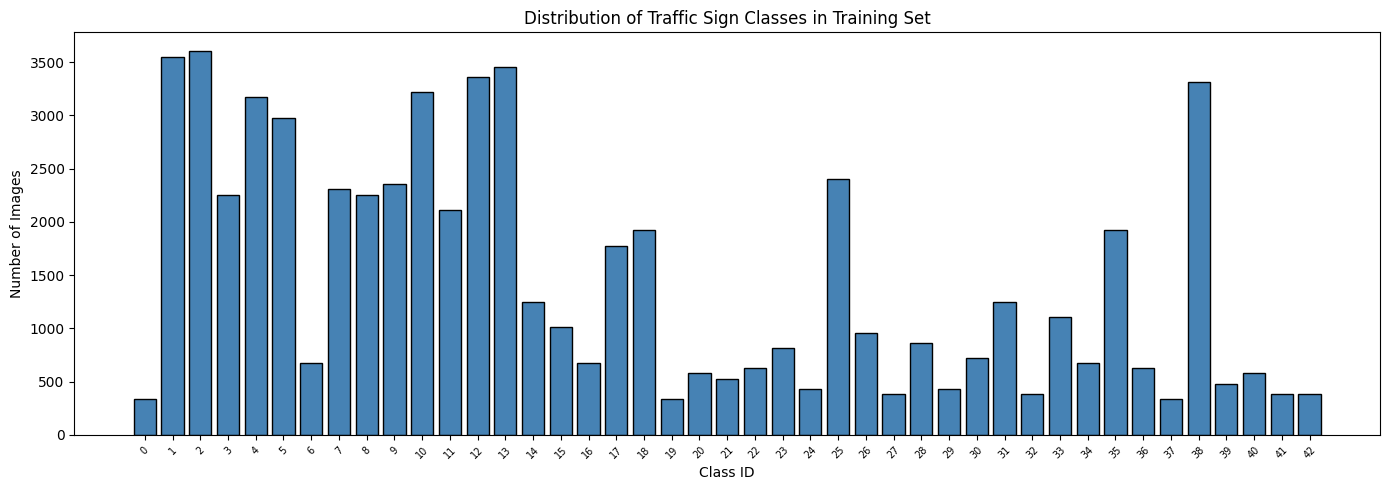

Min samples in a class: 336
Max samples in a class: 3600


In [9]:
# Class distribution
class_counts = Counter(y_train)
classes_sorted = sorted(class_counts.keys())
counts_sorted = [class_counts[c] for c in classes_sorted]

plt.figure(figsize=(14, 5))
plt.bar(range(len(classes_sorted)), counts_sorted, color='steelblue', edgecolor='black')
plt.xlabel('Class ID')
plt.ylabel('Number of Images')
plt.title('Distribution of Traffic Sign Classes in Training Set')
plt.xticks(range(len(classes_sorted)), [str(le.classes_[c]) for c in classes_sorted], fontsize=7, rotation=45)
plt.tight_layout()
plt.show()

print(f"Min samples in a class: {min(counts_sorted)}")
print(f"Max samples in a class: {max(counts_sorted)}")

---
## 4. Data Preprocessing

### HOG (Histogram of Oriented Gradients) Feature Extraction
HOG captures **edge directions and gradient structure** — ideal for recognizing traffic sign shapes (circles, triangles, octagons).  
ML models will use **HOG features** instead of raw pixel values for better accuracy.

In [10]:
# Extract HOG features from images for ML algorithms
def extract_hog_features(images):
    """Extract HOG features from a batch of images."""
    hog_features = []
    for img in images:
        # Convert to grayscale for HOG
        gray = rgb2gray(img)
        # Extract HOG features
        features = hog(gray, orientations=9, pixels_per_cell=(8, 8),
                       cells_per_block=(2, 2), block_norm='L2-Hys')
        hog_features.append(features)
    return np.array(hog_features)

print("Extracting HOG features from training images...")
X_train_hog = extract_hog_features(X_train)

print("Extracting HOG features from test images...")
X_test_hog = extract_hog_features(X_test)

print(f"\nHOG feature shape (train): {X_train_hog.shape}")
print(f"HOG feature shape (test): {X_test_hog.shape}")
print(f"HOG features per image: {X_train_hog.shape[1]}")

Extracting HOG features from training images...
Extracting HOG features from test images...

HOG feature shape (train): (62734, 324)
HOG feature shape (test): (15684, 324)
HOG features per image: 324


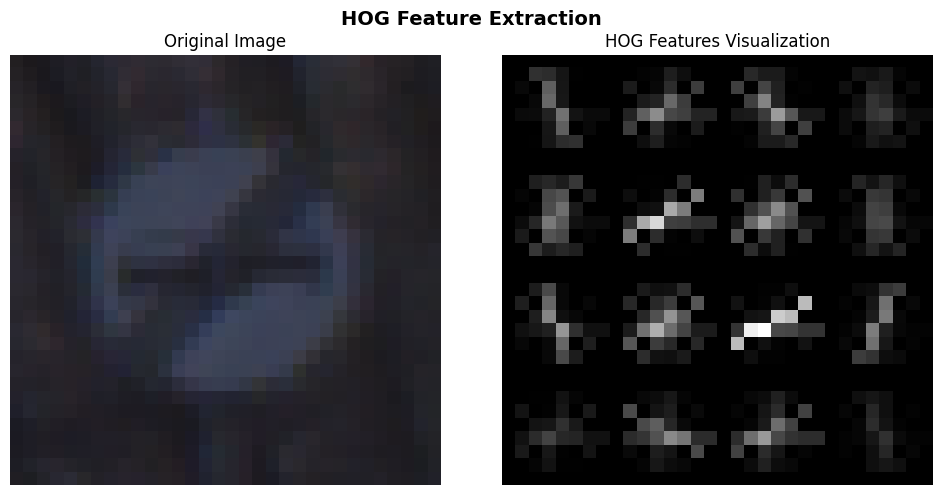

In [11]:
# Visualize HOG features for a sample image
sample_img = rgb2gray(X_train[0])
hog_feat, hog_image = hog(sample_img, orientations=9, pixels_per_cell=(8, 8),
                          cells_per_block=(2, 2), block_norm='L2-Hys', visualize=True)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))
ax1.imshow(X_train[0])
ax1.set_title('Original Image')
ax1.axis('off')

ax2.imshow(hog_image, cmap='gray')
ax2.set_title('HOG Features Visualization')
ax2.axis('off')

plt.suptitle('HOG Feature Extraction', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [12]:
# Scale HOG features for ML algorithms
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_hog)
X_test_scaled = scaler.transform(X_test_hog)

print(f"Scaled HOG training shape: {X_train_scaled.shape}")
print(f"Scaled HOG test shape: {X_test_scaled.shape}")
print("\nFeature scaling done!")

Scaled HOG training shape: (62734, 324)
Scaled HOG test shape: (15684, 324)

Feature scaling done!


In [13]:
# Use a subset for ML if dataset is very large (for faster training)
MAX_ML_TRAIN = 10000
MAX_ML_TEST = 3000

np.random.seed(42)

if len(X_train_scaled) > MAX_ML_TRAIN:
    train_idx = np.random.choice(len(X_train_scaled), size=MAX_ML_TRAIN, replace=False)
    X_train_ml = X_train_scaled[train_idx]
    y_train_ml = y_train[train_idx]
else:
    X_train_ml = X_train_scaled
    y_train_ml = y_train

if len(X_test_scaled) > MAX_ML_TEST:
    test_idx = np.random.choice(len(X_test_scaled), size=MAX_ML_TEST, replace=False)
    X_test_ml = X_test_scaled[test_idx]
    y_test_ml = y_test[test_idx]
else:
    X_test_ml = X_test_scaled
    y_test_ml = y_test

print(f"ML Training samples: {X_train_ml.shape[0]}")
print(f"ML Test samples: {X_test_ml.shape[0]}")

ML Training samples: 10000
ML Test samples: 3000


---
## 5. Machine Learning Algorithms (with HOG Features)

We use **HOG features** (not raw pixels) as input to ML classifiers.  
HOG captures gradient orientations which helps ML models understand shapes and edges.

We will train and evaluate three traditional ML classifiers:
1. **HOG + SVM** (Support Vector Machine)
2. **HOG + Random Forest**
3. **HOG + KNN** (K-Nearest Neighbors)

### 5.1 HOG + Support Vector Machine (SVM)

In [14]:
print("Training HOG + SVM classifier...")
svm_model = SVC(kernel='rbf', C=10, gamma='scale', random_state=42)
svm_model.fit(X_train_ml, y_train_ml)

svm_pred = svm_model.predict(X_test_ml)
svm_accuracy = accuracy_score(y_test_ml, svm_pred)

print(f"\n✅ HOG + SVM Accuracy: {svm_accuracy * 100:.2f}%")

Training HOG + SVM classifier...

✅ HOG + SVM Accuracy: 94.63%


### 5.2 HOG + Random Forest

In [15]:
print("Training HOG + Random Forest classifier...")
rf_model = RandomForestClassifier(n_estimators=200, max_depth=30, random_state=42, n_jobs=-1)
rf_model.fit(X_train_ml, y_train_ml)

rf_pred = rf_model.predict(X_test_ml)
rf_accuracy = accuracy_score(y_test_ml, rf_pred)

print(f"\n✅ HOG + Random Forest Accuracy: {rf_accuracy * 100:.2f}%")

Training HOG + Random Forest classifier...

✅ HOG + Random Forest Accuracy: 88.30%


### 5.3 HOG + K-Nearest Neighbors (KNN)

In [16]:
print("Training HOG + KNN classifier...")
knn_model = KNeighborsClassifier(n_neighbors=5, n_jobs=-1)
knn_model.fit(X_train_ml, y_train_ml)

knn_pred = knn_model.predict(X_test_ml)
knn_accuracy = accuracy_score(y_test_ml, knn_pred)

print(f"\n✅ HOG + KNN Accuracy: {knn_accuracy * 100:.2f}%")

Training HOG + KNN classifier...

✅ HOG + KNN Accuracy: 89.23%


### 5.4 ML Results Summary

   ML RESULTS SUMMARY (with HOG Features)
   HOG + SVM            : 94.63%
   HOG + RF             : 88.30%
   HOG + KNN            : 89.23%


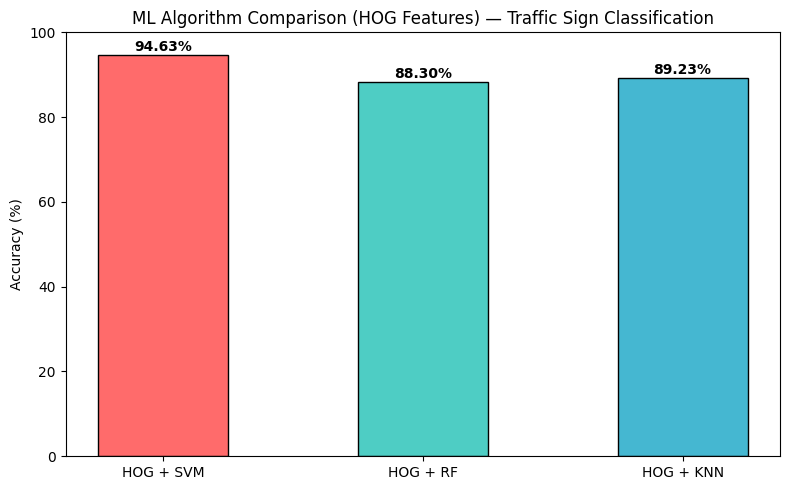

In [17]:
# Compare ML algorithms (all using HOG features)
ml_results = {
    'HOG + SVM': svm_accuracy * 100,
    'HOG + RF': rf_accuracy * 100,
    'HOG + KNN': knn_accuracy * 100
}

print("=" * 50)
print("   ML RESULTS SUMMARY (with HOG Features)")
print("=" * 50)
for model, acc in ml_results.items():
    print(f"   {model:20s} : {acc:.2f}%")
print("=" * 50)

# Visualization
plt.figure(figsize=(8, 5))
colors = ['#FF6B6B', '#4ECDC4', '#45B7D1']
bars = plt.bar(ml_results.keys(), ml_results.values(), color=colors, edgecolor='black', width=0.5)
plt.ylabel('Accuracy (%)')
plt.title('ML Algorithm Comparison (HOG Features) — Traffic Sign Classification')
plt.ylim(0, 100)

for bar, acc in zip(bars, ml_results.values()):
    plt.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 1,
             f'{acc:.2f}%', ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

---
## 6. AI Algorithm — Convolutional Neural Network (CNN)

Deep learning CNN is more suitable for image classification as it can learn spatial features automatically.

In [18]:
# Prepare data for CNN
y_train_cnn = to_categorical(y_train, NUM_CLASSES)
y_test_cnn = to_categorical(y_test, NUM_CLASSES)

print(f"CNN Training data shape: {X_train.shape}")
print(f"CNN Training labels shape: {y_train_cnn.shape}")
print(f"CNN Test data shape: {X_test.shape}")
print(f"CNN Test labels shape: {y_test_cnn.shape}")

CNN Training data shape: (62734, 32, 32, 3)
CNN Training labels shape: (62734, 43)
CNN Test data shape: (15684, 32, 32, 3)
CNN Test labels shape: (15684, 43)


In [19]:
# Build CNN Model
cnn_model = Sequential([
    # Block 1
    Conv2D(32, (3, 3), activation='relu', input_shape=(IMG_SIZE, IMG_SIZE, 3)),
    BatchNormalization(),
    Conv2D(32, (3, 3), activation='relu'),
    MaxPooling2D(pool_size=(2, 2)),
    Dropout(0.25),
    
    # Block 2
    Conv2D(64, (3, 3), activation='relu'),
    BatchNormalization(),
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D(pool_size=(2, 2)),
    Dropout(0.25),
    
    # Fully Connected Layers
    Flatten(),
    Dense(256, activation='relu'),
    BatchNormalization(),
    Dropout(0.5),
    Dense(NUM_CLASSES, activation='softmax')
])

cnn_model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 30, 30, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 12, 12, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 10, 10, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       409,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 43)             │        11,051 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 487,883 (1.86 MB)

 Trainable params: 487,179 (1.86 MB)

 Non-trainable params: 704 (2.75 KB)

In [20]:
# Train the CNN
print("Training CNN model...\n")

history = cnn_model.fit(
    X_train, y_train_cnn,
    epochs=15,
    batch_size=64,
    validation_split=0.2,
    verbose=1
)

print("\n✅ CNN Training Complete!")

Training CNN model...

Epoch 1/15
785/785 ━━━━━━━━━━━━━━━━━━━━ 20s 15ms/step - accuracy: 0.8158 - loss: 0.6982 - val_accuracy: 0.9895 - val_loss: 0.0509
Epoch 2/15
785/785 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9812 - loss: 0.0717 - val_accuracy: 0.9968 - val_loss: 0.0148
Epoch 3/15
785/785 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9898 - loss: 0.0377 - val_accuracy: 0.9971 - val_loss: 0.0121
Epoch 4/15
785/785 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9924 - loss: 0.0272 - val_accuracy: 0.9920 - val_loss: 0.0272
Epoch 5/15
785/785 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9930 - loss: 0.0231 - val_accuracy: 0.9988 - val_loss: 0.0047
Epoch 6/15
785/785 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9941 - loss: 0.0204 - val_accuracy: 0.9950 - val_loss: 0.0169
Epoch 7/15
785/785 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9941 - loss: 0.0187 - val_accuracy: 0.9972 - val_loss: 0.0114
Epoch 8/15
785/785 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9948 - loss: 

In [21]:
# Evaluate CNN on test data
cnn_loss, cnn_accuracy = cnn_model.evaluate(X_test, y_test_cnn, verbose=0)
print(f"\n✅ CNN Test Accuracy: {cnn_accuracy * 100:.2f}%")
print(f"   CNN Test Loss: {cnn_loss:.4f}")


✅ CNN Test Accuracy: 99.97%
   CNN Test Loss: 0.0009


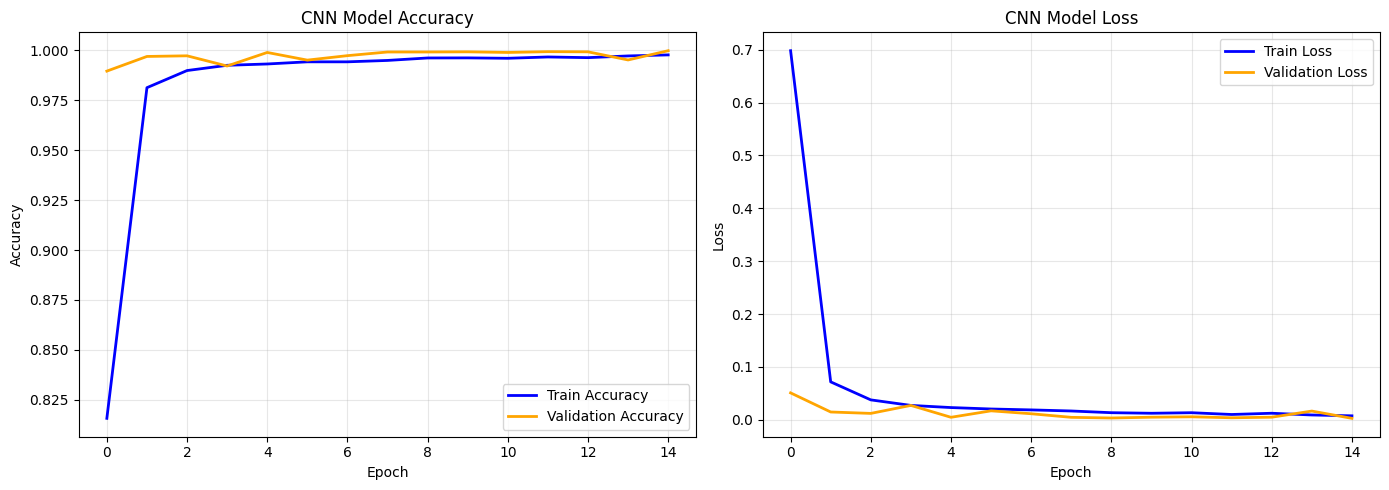

In [22]:
# Plot training history
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy
ax1.plot(history.history['accuracy'], label='Train Accuracy', color='blue', linewidth=2)
ax1.plot(history.history['val_accuracy'], label='Validation Accuracy', color='orange', linewidth=2)
ax1.set_title('CNN Model Accuracy')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Loss
ax2.plot(history.history['loss'], label='Train Loss', color='blue', linewidth=2)
ax2.plot(history.history['val_loss'], label='Validation Loss', color='orange', linewidth=2)
ax2.set_title('CNN Model Loss')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---
### 6.1. CNN — Confusion Matrix & Classification Report

In [23]:
# CNN predictions
cnn_pred = np.argmax(cnn_model.predict(X_test), axis=1)

# Classification report
print("CNN Classification Report:")
print("=" * 65)
print(classification_report(y_test, cnn_pred))

491/491 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step
CNN Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        84
           1       1.00      1.00      1.00       888
           2       1.00      1.00      1.00       900
           3       1.00      1.00      1.00       564
           4       1.00      1.00      1.00       792
           5       1.00      1.00      1.00       744
           6       1.00      1.00      1.00       168
           7       1.00      1.00      1.00       576
           8       1.00      1.00      1.00       564
           9       1.00      1.00      1.00       588
          10       1.00      1.00      1.00       804
          11       1.00      1.00      1.00       528
          12       1.00      1.00      1.00       840
          13       1.00      1.00      1.00       864
          14       1.00      1.00      1.00       312
          15       1.00      1.00      1.00       252
          16 

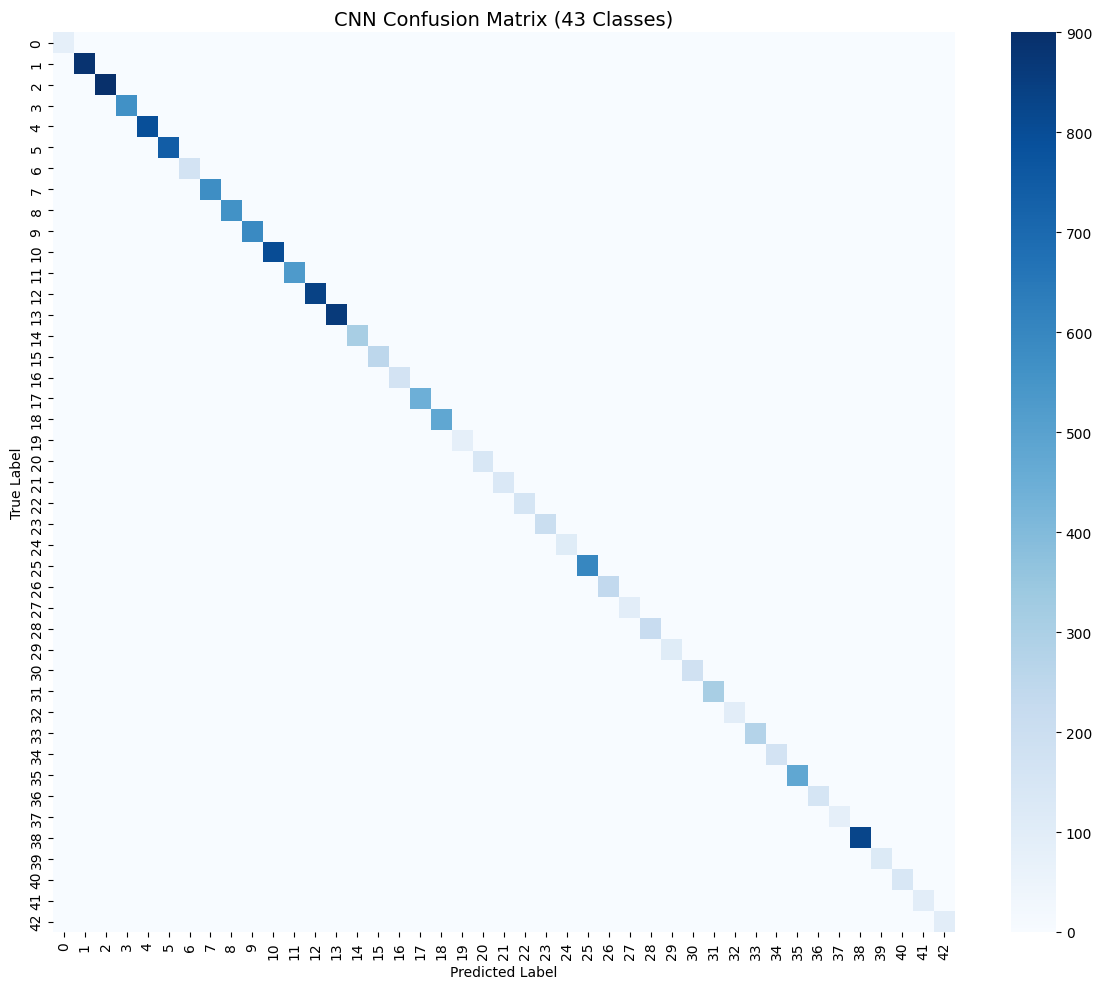

In [24]:
# Confusion matrix (heatmap)
cm = confusion_matrix(y_test, cnn_pred)

plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=(NUM_CLASSES <= 20), fmt='d', cmap='Blues',
            xticklabels=range(NUM_CLASSES), yticklabels=range(NUM_CLASSES))
plt.title(f'CNN Confusion Matrix ({NUM_CLASSES} Classes)', fontsize=14)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.show()

---
## 7. Transfer Learning — MobileNetV2
Using a pre-trained MobileNetV2 model to extract features.

In [25]:
import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, BatchNormalization, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

# 1. Data Augmentation Layer (Applied only during training automatically)
data_augmentation = Sequential([
    tf.keras.layers.RandomFlip('horizontal'),
    tf.keras.layers.RandomRotation(0.2),
    tf.keras.layers.RandomZoom(0.2),
], name="data_augmentation")

# 2. Setup Base Model
# Note: Keras applications have built-in preprocessing, but scaling to [-1, 1] manually as you did is also fine.
X_train_mb = (X_train * 2.0) - 1.0
X_test_mb = (X_test * 2.0) - 1.0

base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))
base_model.trainable = False # Freeze base model for Phase 1

# 3. Build the Improved Architecture
mobilenet_model = Sequential([
    data_augmentation,
    base_model,
    GlobalAveragePooling2D(), # Replaced Flatten() to prevent massive overfitting
    Dense(256, activation='relu'),
    BatchNormalization(),
    Dropout(0.3),
    Dense(NUM_CLASSES, activation='softmax')
])

# 4. Define Callbacks for Smart Training
callbacks = [
    EarlyStopping(monitor='val_accuracy', patience=5, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6, verbose=1)
]

### 7.1 PHASE 1: Feature Extraction

In [26]:
print("\n--- Phase 1: Training Classification Head ---")
mobilenet_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.01), 
                        loss='categorical_crossentropy', 
                        metrics=['accuracy'])

history_phase1 = mobilenet_model.fit(
    X_train_mb, y_train_cnn, 
    epochs=30, # Increased epochs because EarlyStopping will catch it if it finishes early
    batch_size=64, 
    validation_split=0.2, 
    callbacks=callbacks,
    verbose=1
)


--- Phase 1: Training Classification Head ---
Epoch 1/30
785/785 ━━━━━━━━━━━━━━━━━━━━ 25s 18ms/step - accuracy: 0.1969 - loss: 2.8095 - val_accuracy: 0.1948 - val_loss: 2.7303 - learning_rate: 0.0100
Epoch 2/30
785/785 ━━━━━━━━━━━━━━━━━━━━ 12s 15ms/step - accuracy: 0.2271 - loss: 2.6219 - val_accuracy: 0.2035 - val_loss: 2.6840 - learning_rate: 0.0100
Epoch 3/30
785/785 ━━━━━━━━━━━━━━━━━━━━ 21s 16ms/step - accuracy: 0.2376 - loss: 2.5804 - val_accuracy: 0.2256 - val_loss: 2.6413 - learning_rate: 0.0100
Epoch 4/30
785/785 ━━━━━━━━━━━━━━━━━━━━ 12s 15ms/step - accuracy: 0.2441 - loss: 2.5610 - val_accuracy: 0.2159 - val_loss: 2.6383 - learning_rate: 0.0100
Epoch 5/30
785/785 ━━━━━━━━━━━━━━━━━━━━ 12s 15ms/step - accuracy: 0.2444 - loss: 2.5518 - val_accuracy: 0.2233 - val_loss: 2.6241 - learning_rate: 0.0100
Epoch 6/30
785/785 ━━━━━━━━━━━━━━━━━━━━ 12s 15ms/step - accuracy: 0.2454 - loss: 2.5442 - val_accuracy: 0.2234 - val_loss: 2.6153 - learning_rate: 0.0100
Epoch 7/30
785/785 ━━━━━━━━━━

### 7.2 PHASE 2: Fine-Tuning & Final Evaluation

In [27]:
print("\n--- Phase 2: Fine-Tuning Top Layers of Base Model ---")
# Unfreeze the base model
base_model.trainable = True

# Freeze the bottom layers, only fine-tune the top ~30 layers
for layer in base_model.layers[:120]: 
    layer.trainable = False

# Recompile with a MUCH lower learning rate to avoid destroying the pre-trained weights
mobilenet_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5), 
                        loss='categorical_crossentropy', 
                        metrics=['accuracy'])

history_phase2 = mobilenet_model.fit(
    X_train_mb, y_train_cnn, 
    epochs=10, 
    batch_size=64, 
    validation_split=0.2, 
    callbacks=callbacks,
    verbose=1
)

# 5. Final Evaluation
_, mb_accuracy = mobilenet_model.evaluate(X_test_mb, y_test_cnn, verbose=0)
print(f"\n✅ Optimized MobileNetV2 Test Accuracy: {mb_accuracy * 100:.2f}%")


--- Phase 2: Fine-Tuning Top Layers of Base Model ---
Epoch 1/10
785/785 ━━━━━━━━━━━━━━━━━━━━ 37s 33ms/step - accuracy: 0.1584 - loss: 3.1876 - val_accuracy: 0.0850 - val_loss: 3.4091 - learning_rate: 1.0000e-05
Epoch 2/10
783/785 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.2110 - loss: 2.7496
Epoch 2: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-06.
785/785 ━━━━━━━━━━━━━━━━━━━━ 23s 29ms/step - accuracy: 0.2247 - loss: 2.6768 - val_accuracy: 0.1038 - val_loss: 3.2955 - learning_rate: 1.0000e-05
Epoch 3/10
785/785 ━━━━━━━━━━━━━━━━━━━━ 23s 30ms/step - accuracy: 0.2586 - loss: 2.5062 - val_accuracy: 0.1716 - val_loss: 3.0034 - learning_rate: 5.0000e-06
Epoch 4/10
783/785 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.2677 - loss: 2.4537
Epoch 4: ReduceLROnPlateau reducing learning rate to 2.499999936844688e-06.
785/785 ━━━━━━━━━━━━━━━━━━━━ 24s 31ms/step - accuracy: 0.2758 - loss: 2.4219 - val_accuracy: 0.2389 - val_loss: 2.6947 - learning_rate: 5.0000e-06
Epoch 5/1

---
## 8. Final Comparison — ML vs Custom CNN vs Transfer Learning

     FINAL RESULTS: ML vs AI vs TL COMPARISON
    HOG + SVM                 : 94.63%
    HOG + RF                  : 88.30%
    HOG + KNN                 : 89.23%
 ⭐ Custom CNN                : 99.97%
    MobileNetV2 (TL)          : 33.68%


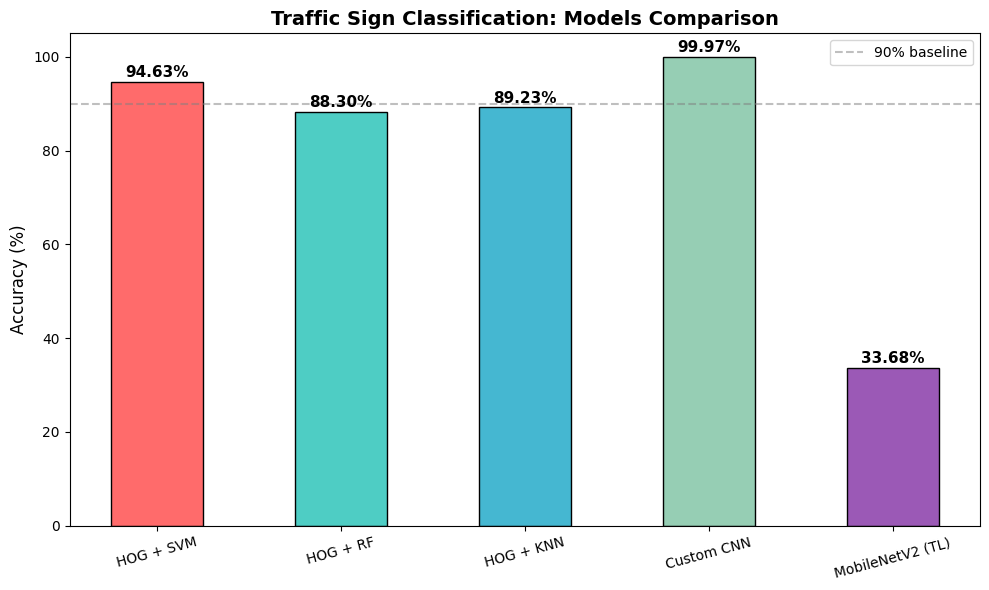

In [28]:
all_results = {
    'HOG + SVM': svm_accuracy * 100,
    'HOG + RF': rf_accuracy * 100,
    'HOG + KNN': knn_accuracy * 100,
    'Custom CNN': cnn_accuracy * 100,
    'MobileNetV2 (TL)': mb_accuracy * 100
}

print("=" * 60)
print("     FINAL RESULTS: ML vs AI vs TL COMPARISON")
print("=" * 60)
for model, acc in all_results.items():
    marker = "⭐" if acc == max(all_results.values()) else "  "
    print(f" {marker} {model:25s} : {acc:.2f}%")
print("=" * 60)

plt.figure(figsize=(10, 6))
colors = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#96CEB4', '#9B59B6']
plt.xticks(rotation=15)
bars = plt.bar(all_results.keys(), all_results.values(), color=colors, edgecolor='black', width=0.5)

plt.ylabel('Accuracy (%)', fontsize=12)
plt.title('Traffic Sign Classification: Models Comparison', fontsize=14, fontweight='bold')
plt.ylim(0, 105)

for bar, acc in zip(bars, all_results.values()):
    plt.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 1,
             f'{acc:.2f}%', ha='center', fontweight='bold', fontsize=11)

plt.axhline(y=90, color='gray', linestyle='--', alpha=0.5, label='90% baseline')
plt.legend()
plt.tight_layout()
plt.show()

---
## 9. Test with Sample Predictions

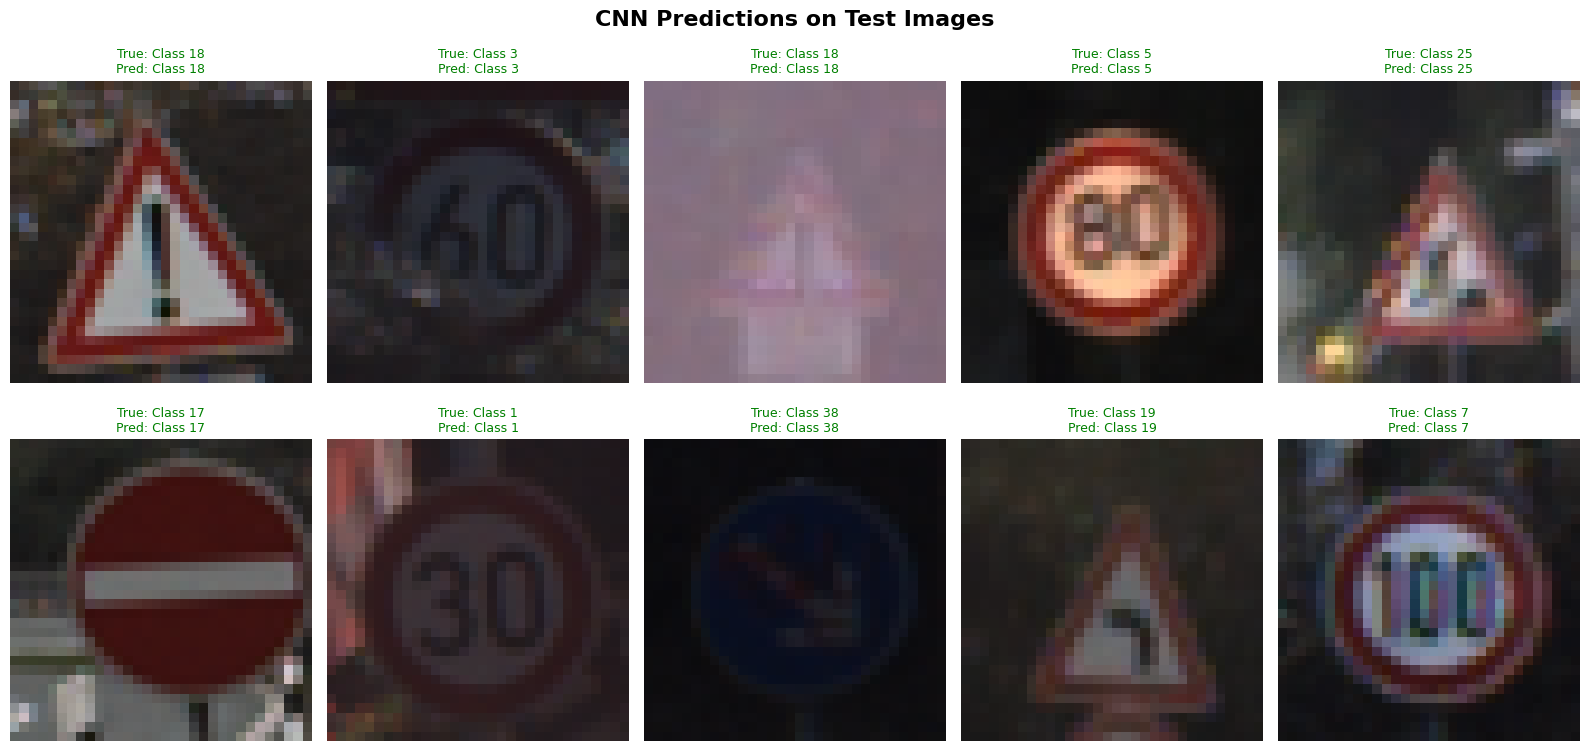

In [29]:
# Visualize CNN predictions on random test images
fig, axes = plt.subplots(2, 5, figsize=(16, 8))
fig.suptitle('CNN Predictions on Test Images', fontsize=16, fontweight='bold')

random_indices = np.random.choice(len(X_test), 10, replace=False)

for i, ax in enumerate(axes.flat):
    idx = random_indices[i]
    ax.imshow(X_test[idx])
    
    true_label = y_test[idx]
    pred_label = cnn_pred[idx]
    
    color = 'green' if true_label == pred_label else 'red'
    ax.set_title(f"True: Class {le.classes_[true_label]}\n"
                 f"Pred: Class {le.classes_[pred_label]}",
                 fontsize=9, color=color)
    ax.axis('off')

plt.tight_layout()
plt.show()

---
## 10. Conclusion

### Key Findings:

| Algorithm | Type | Key Characteristics |
|-----------|------|--------------------|
| **HOG + SVM** | ML | HOG extracts edge gradients; SVM uses kernel trick for classification |
| **HOG + Random Forest** | ML | HOG features + ensemble of decision trees |
| **HOG + KNN** | ML | HOG features + distance-based nearest neighbor classifier |
| **CNN** | AI/DL | Learns spatial features automatically, best for images |

### Why HOG for ML?
- **HOG (Histogram of Oriented Gradients)** captures edge directions and gradient magnitudes
- Traffic signs have distinct shapes (circles, triangles, octagons) that HOG can represent effectively
- Using HOG features instead of raw pixels significantly improves ML model accuracy

### Observations:
1. **CNN (Deep Learning)** outperforms all traditional ML algorithms because it can learn hierarchical spatial features (edges → shapes → patterns → signs)
2. **HOG + SVM** performs well because HOG captures edge gradients and SVM handles high-dimensional feature spaces
3. **HOG + Random Forest** provides decent accuracy with an ensemble approach on HOG features
4. **HOG + KNN** is the simplest ML approach but benefits from HOG's shape descriptors

### Summary:
- **ML algorithms with HOG** use handcrafted edge/gradient features to classify signs
- **AI (CNN)** automatically learns optimal features from raw pixels
- For image classification tasks like traffic sign detection, **deep learning is clearly superior**
